# PPG Feature Extraction

This notebook turns the raw recordings in `Part_1.mat` into a table for model training:

1. Split each recording into 5-second windows (625 samples at 125 Hz).
2. Get the SBP/DBP labels from the ABP peaks and valleys, plus a low/normal/elevated/high category.
3. Discard noisy or physiologically impossible windows.
4. Extract PPG features for each window.
5. Save the result to `data/ppg_features_part1.csv`.

The `.mat` files are not in the repo. Download them from [UCI](https://archive.ics.uci.edu/dataset/340/cuff%2Bless%2Bblood%2Bpressure%2Bestimation) into `data/`.

In [1]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import skew, kurtosis

DATA_FILE = '../data/Part_1.mat'
OUTPUT_FILE = '../data/ppg_features_part1.csv'

FS = 125                  # sampling rate (Hz)
WINDOW = FS * 5           # 5-second window = 625 samples
MAX_RECORDS = None        # set to e.g. 200 for a quick test run

## Load the data

The file is MATLAB v7.3, so `scipy.io.loadmat` can't read it; it is opened with `h5py` instead. It contains 3,000 recordings. Each recording is an array of shape `(n_samples, 3)` with the columns PPG, ABP (mmHg) and ECG. The ECG is not used.

In [2]:
def load_record(f, i):
    return f[f['Part_1'][i][0]][:]

with h5py.File(DATA_FILE, 'r') as f:
    n_records = f['Part_1'].shape[0]
    example = load_record(f, 0)

print('Number of recordings:', n_records)
print('First recording shape:', example.shape)

Number of recordings: 3000
First recording shape: (61000, 3)


## Clean the PPG and find beats

- **Filter:** a 0.5–8 Hz band-pass filter removes slow baseline drift and high-frequency noise. It is applied to the whole recording before splitting it into windows.
- **Peaks:** found with `find_peaks`, at least 0.33 s apart (max ~180 bpm).
- **Feet:** the minimum between two neighbouring peaks.
- **Complete beats:** only beats with a foot on both sides of the peak are measured.

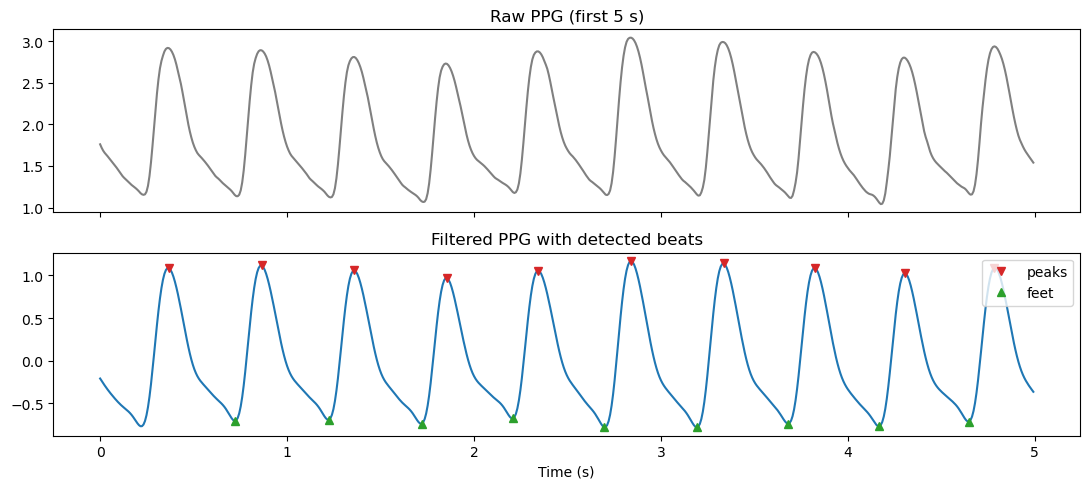

In [3]:
def bandpass(signal, low=0.5, high=8.0, fs=FS, order=3):
    b, a = butter(order, [low, high], btype='band', fs=fs)
    return filtfilt(b, a, signal)


def find_beats(ppg, fs=FS):
    # Returns peak indices and a list of complete beats as (foot, peak, next_foot)
    peaks, _ = find_peaks(ppg, distance=int(0.33 * fs), prominence=0.3 * np.std(ppg))
    beats = []
    for k in range(1, len(peaks) - 1):
        foot = peaks[k - 1] + np.argmin(ppg[peaks[k - 1]:peaks[k]])
        next_foot = peaks[k] + np.argmin(ppg[peaks[k]:peaks[k + 1]])
        beats.append((foot, peaks[k], next_foot))
    return peaks, beats


ppg_raw = example[:WINDOW, 0]
ppg_clean = bandpass(example[:, 0])[:WINDOW]
peaks, beats = find_beats(ppg_clean)
feet = sorted({b[0] for b in beats} | {b[2] for b in beats})

t = np.arange(WINDOW) / FS
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(t, ppg_raw, color='gray')
axes[0].set_title('Raw PPG (first 5 s)')
axes[1].plot(t, ppg_clean)
axes[1].plot(t[peaks], ppg_clean[peaks], 'v', color='tab:red', label='peaks')
axes[1].plot(t[feet], ppg_clean[feet], '^', color='tab:green', label='feet')
axes[1].set_title('Filtered PPG with detected beats')
axes[1].set_xlabel('Time (s)')
axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

## Features

Each feature is computed per window. Per-beat features are averaged over the complete beats in the window.

| Feature | Description |
|---|---|
| `heart_rate_bpm` | beats per minute, from the time between peaks |
| `hrv_std_ms` | heart rate variability: standard deviation of the time between peaks |
| `pulse_height` | foot-to-peak amplitude |
| `rise_time_s` | time from foot to peak |
| `fall_time_s` | time from peak to next foot |
| `rise_fall_ratio` | rise time / fall time |
| `pulse_width_s` | time the pulse stays above half its height |
| `max_upslope` | steepest slope between foot and peak |
| `ppg_mean` | mean of the raw PPG (the filtered signal is centred at 0) |
| `ppg_std`, `ppg_min`, `ppg_max`, `ppg_range` | basic statistics of the filtered PPG |
| `ppg_skewness`, `ppg_kurtosis` | shape of the signal's value distribution |

In [4]:
def extract_ppg_features(ppg_window, ppg_raw_window, fs=FS):
    peaks, beats = find_beats(ppg_window, fs)
    if len(beats) < 2:  # not enough beats for reliable averages
        return None

    rise, fall, height, width, upslope = [], [], [], [], []
    for foot, peak, next_foot in beats:
        h = ppg_window[peak] - ppg_window[foot]
        rise.append((peak - foot) / fs)
        fall.append((next_foot - peak) / fs)
        height.append(h)
        width.append(np.sum(ppg_window[foot:next_foot + 1] >= ppg_window[foot] + 0.5 * h) / fs)
        upslope.append(np.max(np.diff(ppg_window[foot:peak + 1])) * fs)

    intervals = np.diff(peaks) / fs
    rise, fall = np.array(rise), np.array(fall)

    return {
        'heart_rate_bpm': 60 / np.mean(intervals),
        'hrv_std_ms': np.std(intervals) * 1000,
        'pulse_height': np.mean(height),
        'rise_time_s': np.mean(rise),
        'fall_time_s': np.mean(fall),
        'rise_fall_ratio': np.mean(rise / fall),
        'pulse_width_s': np.mean(width),
        'max_upslope': np.mean(upslope),
        'ppg_mean': np.mean(ppg_raw_window),
        'ppg_std': np.std(ppg_window),
        'ppg_min': np.min(ppg_window),
        'ppg_max': np.max(ppg_window),
        'ppg_range': np.ptp(ppg_window),
        'ppg_skewness': skew(ppg_window),
        'ppg_kurtosis': kurtosis(ppg_window),
        'n_beats': len(beats),
    }

pd.Series(extract_ppg_features(ppg_clean, ppg_raw)).round(3)

heart_rate_bpm     122.283
hrv_std_ms           6.532
pulse_height         1.814
rise_time_s          0.140
fall_time_s          0.351
rise_fall_ratio      0.399
pulse_width_s        0.174
max_upslope         22.565
ppg_mean             1.842
ppg_std              0.598
ppg_min             -0.782
ppg_max              1.170
ppg_range            1.952
ppg_skewness         0.566
ppg_kurtosis        -1.101
n_beats              8.000
dtype: float64

## Blood pressure labels

For each window, SBP is the average of the ABP peaks and DBP is the average of the ABP valleys.

In [5]:
def extract_bp_labels(abp_window, fs=FS):
    peaks, _ = find_peaks(abp_window, distance=int(0.33 * fs), prominence=10)
    valleys, _ = find_peaks(-abp_window, distance=int(0.33 * fs), prominence=10)
    if len(peaks) < 2 or len(valleys) < 2:
        return None
    return {'sbp': np.mean(abp_window[peaks]), 'dbp': np.mean(abp_window[valleys])}

extract_bp_labels(example[:WINDOW, 1])

{'sbp': np.float64(121.548553481852), 'dbp': np.float64(66.9652669574519)}

## Discard noisy windows

A window is skipped if:
- the PPG is clipped at the sensor limits (0 or 4);
- the PPG or ABP signal is flat;
- the window has too few detectable beats;
- the values are physiologically impossible: heart rate outside 40–180 bpm, very irregular beat intervals, SBP outside 70–200 mmHg, DBP outside 40–120 mmHg, or DBP ≥ SBP.

In [6]:
def window_is_clean(ppg_raw_window, abp_window):
    clipped = np.mean((ppg_raw_window <= 0.01) | (ppg_raw_window >= 3.99)) > 0.01
    flat_ppg = np.std(ppg_raw_window) < 0.01
    flat_abp = np.ptp(abp_window) < 10
    return not (clipped or flat_ppg or flat_abp)


def features_are_plausible(feats, labels):
    return (
        40 <= feats['heart_rate_bpm'] <= 180
        and feats['hrv_std_ms'] < 200
        and 70 <= labels['sbp'] <= 200
        and 40 <= labels['dbp'] <= 120
        and labels['dbp'] < labels['sbp']
    )

## Process all recordings

Each row keeps its `record` number. When splitting into train/test sets later, split by `record`, so that windows from the same recording don't end up on both sides.

In [7]:
rows = []
skipped = {'bad_signal': 0, 'too_few_beats': 0, 'implausible': 0}

with h5py.File(DATA_FILE, 'r') as f:
    n = n_records if MAX_RECORDS is None else min(MAX_RECORDS, n_records)
    for rec in range(n):
        data = load_record(f, rec)
        if len(data) < 2 * WINDOW:  # too short to filter
            continue
        ppg_all_raw, abp_all = data[:, 0], data[:, 1]
        ppg_all_clean = bandpass(ppg_all_raw)

        for w, start in enumerate(range(0, len(data) - WINDOW + 1, WINDOW)):
            sl = slice(start, start + WINDOW)
            if not window_is_clean(ppg_all_raw[sl], abp_all[sl]):
                skipped['bad_signal'] += 1
                continue
            feats = extract_ppg_features(ppg_all_clean[sl], ppg_all_raw[sl])
            labels = extract_bp_labels(abp_all[sl])
            if feats is None or labels is None:
                skipped['too_few_beats'] += 1
                continue
            if not features_are_plausible(feats, labels):
                skipped['implausible'] += 1
                continue
            rows.append({'record': rec, 'window': w, **feats, **labels})

        if (rec + 1) % 500 == 0:
            print(f'{rec + 1}/{n} records processed')

df = pd.DataFrame(rows)
total = len(df) + sum(skipped.values())
print(f'Kept {len(df)} of {total} windows')
print('Skipped:', skipped)

500/3000 records processed


1000/3000 records processed


1500/3000 records processed


2000/3000 records processed


3000/3000 records processed


Kept 127678 of 130870 windows
Skipped: {'bad_signal': 1180, 'too_few_beats': 141, 'implausible': 1871}


In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
record,127678.0,1332.45,847.13,0.00,512.00,1303.00,2053.00,2999.00
window,127678.0,39.46,29.30,0.00,14.00,34.00,61.00,117.00
heart_rate_bpm,127678.0,87.26,18.01,43.35,73.10,84.59,98.68,180.00
hrv_std_ms,127678.0,30.87,41.89,0.00,5.90,10.33,38.08,199.99
pulse_height,127678.0,1.61,0.48,0.17,1.54,1.80,1.91,2.58
rise_time_s,127678.0,0.21,0.06,0.11,0.16,0.19,0.23,0.72
fall_time_s,127678.0,0.51,0.14,0.13,0.42,0.51,0.61,1.17
rise_fall_ratio,127678.0,0.48,0.33,0.14,0.31,0.37,0.47,2.92
pulse_width_s,127678.0,0.24,0.06,0.10,0.19,0.24,0.28,0.63
max_upslope,127678.0,16.75,5.51,1.47,15.11,18.18,20.39,28.91


## Blood pressure category

A category column is also added for classification. The thresholds are the commonly used adult cut-offs: low is below 90/60 mmHg, and elevated/high follow the AHA guidelines. Each window gets the first category that matches, in this order:

| Category | Rule |
|---|---|
| `high` | SBP ≥ 130 or DBP ≥ 80 |
| `low` | SBP < 90 or DBP < 60 |
| `elevated` | SBP 120–129 (and DBP < 80) |
| `normal` | everything else (SBP < 120 and DBP 60–79) |

In [9]:
def bp_category(sbp, dbp):
    return np.select(
        [(sbp >= 130) | (dbp >= 80), (sbp < 90) | (dbp < 60), sbp >= 120],
        ['high', 'low', 'elevated'],
        default='normal',
    )

df['bp_category'] = bp_category(df['sbp'], df['dbp'])
df['bp_category'].value_counts()

bp_category
high        67664
low         29884
normal      19728
elevated    10402
Name: count, dtype: int64

## Which features relate to blood pressure?

This is a quick check of how strongly each feature moves with SBP and DBP. The score is the correlation, from −1 to +1, where 0 means no linear relationship. It looks at one feature at a time, so a weak feature can still help a model when combined with others.

In [10]:
feature_cols = [c for c in df.columns if c not in ('record', 'window', 'n_beats', 'sbp', 'dbp', 'bp_category')]

corr = df[feature_cols + ['sbp', 'dbp']].corr()[['sbp', 'dbp']].drop(['sbp', 'dbp'])
corr.reindex(corr['sbp'].abs().sort_values(ascending=False).index).round(2)

,sbp,dbp
fall_time_s,0.36,-0.06
ppg_std,0.33,-0.00
heart_rate_bpm,-0.33,0.07
pulse_height,0.30,-0.01
rise_fall_ratio,-0.28,-0.06
ppg_range,0.28,0.02
ppg_max,0.27,-0.05
max_upslope,0.24,0.01
ppg_min,-0.24,-0.13
ppg_mean,0.22,0.05


**Takeaways for modelling**

- **SBP:** the strongest features are `fall_time_s`, `ppg_std`, `heart_rate_bpm`, `pulse_height` and `rise_fall_ratio` (|r| ≈ 0.3). The relationships are weak to moderate, but real.
- **DBP:** no single feature is strongly related (all |r| ≤ 0.2), so DBP will be harder to predict.
- **Overlap:** `pulse_height`, `ppg_std`, `ppg_range` and `ppg_max` all measure how big the pulse is, so they carry similar information.
- **Weakest features:** `hrv_std_ms`, `rise_time_s` and `ppg_skewness` show almost no relationship with SBP.

**Suggestion:** start the baseline models with all 15 features, then compare against a smaller set to see which features actually matter.

## Save

In [11]:
df.to_csv(OUTPUT_FILE, index=False)
print(f'Saved {len(df)} rows to {OUTPUT_FILE}')
df.head()

Saved 127678 rows to ../data/ppg_features_part1.csv


,record,window,heart_rate_bpm,hrv_std_ms,pulse_height,rise_time_s,fall_time_s,rise_fall_ratio,pulse_width_s,max_upslope,...,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis,n_beats,sbp,dbp,bp_category
0,0,0,122.282609,6.531973,1.813675,0.140000,0.351000,0.399019,0.174000,22.565088,...,0.597956,-0.781994,1.170041,1.952035,0.565720,-1.100639,8,121.548553,66.965267,elevated
1,0,1,124.538745,3.325918,1.833584,0.141000,0.341000,0.413552,0.174000,22.515421,...,0.610240,-0.839073,1.125238,1.964311,0.556218,-1.126886,8,124.698998,68.821343,elevated
2,0,2,123.558484,3.666061,1.840527,0.143111,0.342222,0.418236,0.175111,22.483835,...,0.622769,-0.813614,1.174565,1.988180,0.473515,-1.229513,9,125.729609,69.495392,elevated
3,0,3,123.175182,4.532462,1.846716,0.140000,0.348000,0.402418,0.171000,22.905324,...,0.608763,-0.875011,1.166518,2.041529,0.520074,-1.139393,8,122.168874,67.302291,elevated
4,0,4,124.309392,6.531973,1.873393,0.140000,0.342000,0.409522,0.173000,23.127508,...,0.614460,-0.846043,1.148492,1.994535,0.565535,-1.101957,8,125.529348,69.334206,elevated
